# Demo VIB-Net: phát hiện ảnh do AI sinh bằng Variational Information Bottleneck

Mô phỏng thu nhỏ bài **"Towards Universal AI-Generated Image Detection by Variational Information Bottleneck Network"** (CVPR 2025), chạy được trên CPU.

**Câu hỏi của demo:** chỉ huấn luyện trên ảnh **SD15 vs ảnh thật**, bộ phân loại có khối VIB có tổng quát hoá sang generator **chưa gặp** tốt hơn bộ phân loại tuyến tính trên CLIP (kiểu Univfd) không?

Nội dung:
1. Chuẩn bị môi trường và dữ liệu (Tiny-GenImage)
2. Trích đặc trưng CLIP ViT-L/14 (đóng băng) bằng code CLIP của repo tác giả
3. Kiến trúc VIB-head và hàm mất mát
4. Huấn luyện thử một lần, xem đường loss
5. Thí nghiệm so sánh: Linear vs VIB với nhiều β, 3 seed
6. UMAP kiểu Hình 3 của bài
7. Thử dự đoán trên từng ảnh
8. Kết luận và giới hạn

> Notebook dùng lại cache: nếu đã có `data/` và `features.npz` (từ các script `01`, `02`) thì bỏ qua bước tải/trích đặc trưng.

## 1. Môi trường và cấu hình

In [1]:
import json, sys, time, runpy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

HERE = Path.cwd()                      # chạy notebook từ thư mục demo/
assert (HERE / "vib.py").exists(), "Hãy mở notebook trong thư mục demo/"
REPO_MODELS = HERE.parent / "VIBAIGCDetect" / "models"
sys.path.insert(0, str(REPO_MODELS))   # để `import clip` lấy bản CLIP của repo tác giả

from vib import VIBHead, LinearHead, train_head, predict, ap_acc, kl_to_std_normal

torch.set_num_threads(max(1, torch.get_num_threads()))
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.14.1+cpu | cuda: False


## 2. Dữ liệu

Nguồn: [`TheKernel01/Tiny-GenImage`](https://huggingface.co/datasets/TheKernel01/Tiny-GenImage) (bản nhỏ của GenImage). Bộ này **không có SD v1.4** như trong bài, nên dùng **SD15** (cùng họ Stable Diffusion) để huấn luyện.

| Tập | Nội dung |
|---|---|
| train | 200 ảnh thật + 200 ảnh SD15 |
| unseen | 160 ảnh thật + 80 ảnh mỗi generator: ADM, BigGAN, GLIDE, Midjourney, VQDM, Wukong |

Mọi ảnh được resize cạnh ngắn → 256, center-crop 224, lưu JPEG q95, để giảm rò rỉ nhãn qua định dạng/kích thước (GenImage gốc: ảnh thật là JPEG, ảnh giả là PNG).

Bước tải chỉ chạy nếu chưa có `data/meta.json` (khoảng 1.4GB parquet).

In [2]:
if not (HERE / "data/meta.json").exists():
    runpy.run_path(str(HERE / "01_get_data.py"), run_name="__main__")

meta = json.loads((HERE / "data/meta.json").read_text())
df = pd.DataFrame(meta)
df.groupby(["split", "generator"]).size().unstack(0).fillna(0).astype(int)

split,train,unseen
generator,,
ADM,0,80
BigGAN,0,80
GLIDE,0,80
Midjourney,0,80
Real,200,160
SD15,200,0
VQDM,0,80
Wukong,0,80


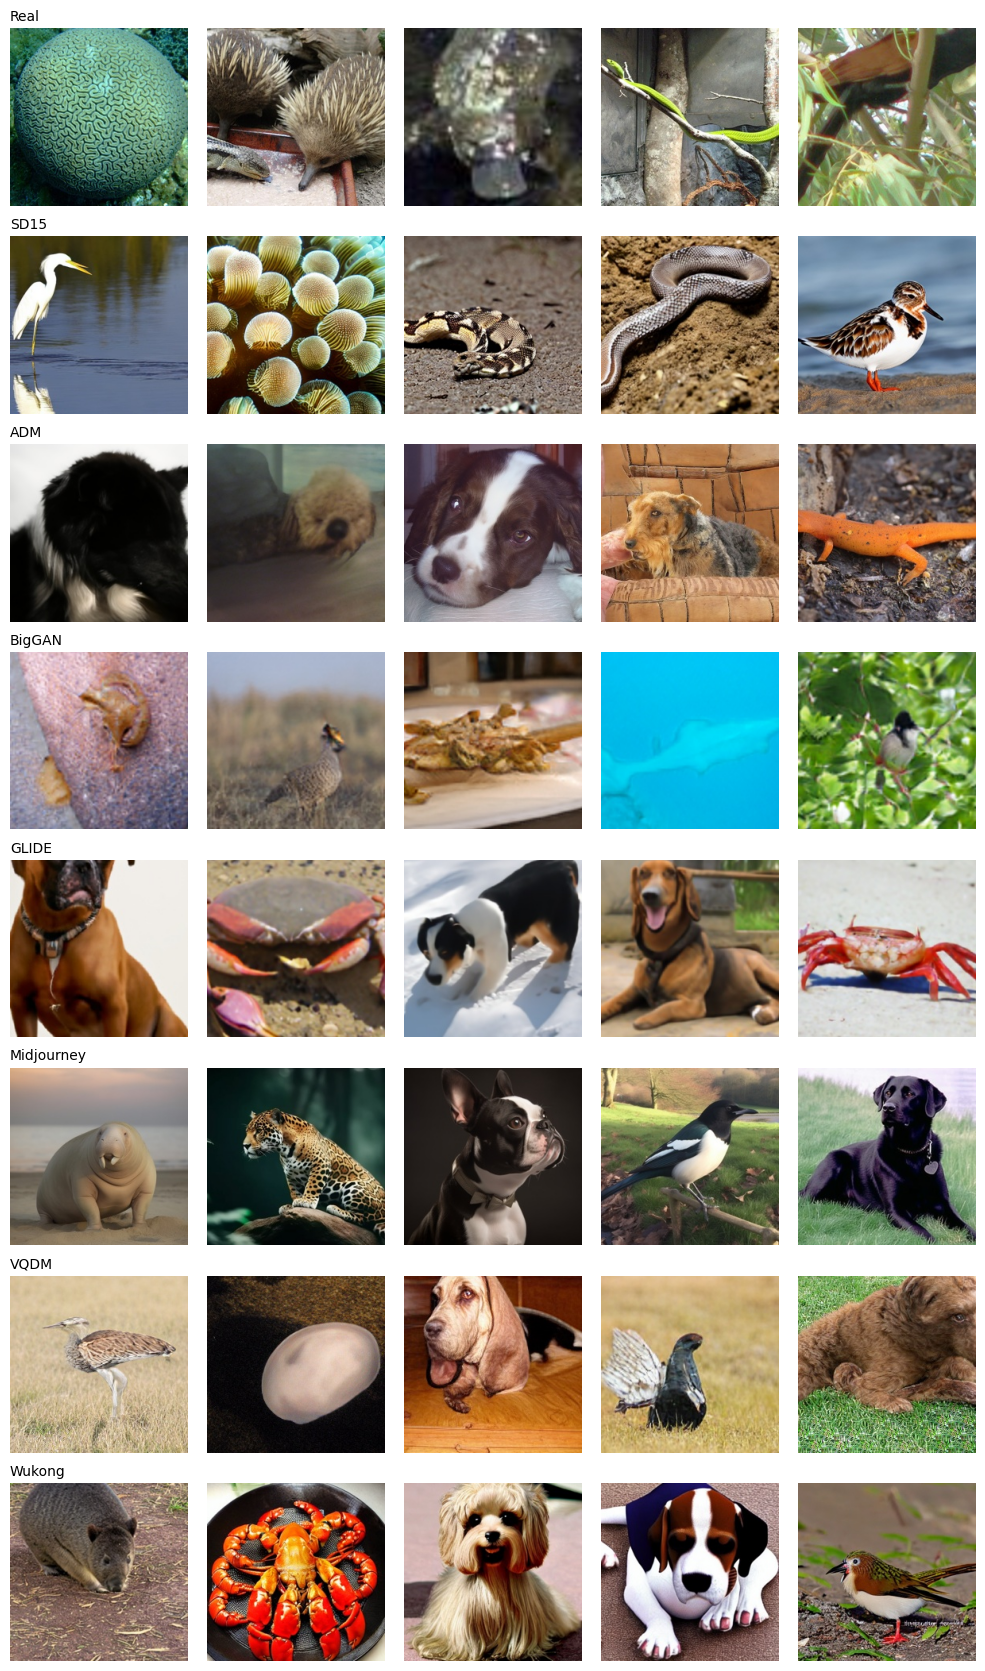

In [3]:
# Xem vài ảnh mỗi nguồn
gens = ["Real", "SD15", "ADM", "BigGAN", "GLIDE", "Midjourney", "VQDM", "Wukong"]
fig, axes = plt.subplots(len(gens), 5, figsize=(10, 2.1 * len(gens)))
for r, g in enumerate(gens):
    paths = df[df.generator == g].path.tolist()[:5]
    for c, p in enumerate(paths):
        axes[r, c].imshow(Image.open(HERE / "data" / p)); axes[r, c].axis("off")
    axes[r, 0].set_title(g, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 3. Trích đặc trưng CLIP ViT-L/14

Giống bài báo, CLIP được **đóng băng**: chỉ cần trích đặc trưng 768 chiều **một lần**, sau đó mọi thí nghiệm huấn luyện trên đặc trưng đã cache nên rất nhanh.

- Dùng `clip.load` trong `VIBAIGCDetect/models/clip` (bản tác giả).
- Tiền xử lý như `main.py`: chuẩn hoá theo mean/std của CLIP.
- Trên CPU bước này mất khoảng **15–20 phút** cho 1040 ảnh (lần đầu còn tải trọng số CLIP 890MB). Chỉ chạy nếu chưa có `features.npz`.

In [4]:
if not (HERE / "features.npz").exists():
    runpy.run_path(str(HERE / "02_extract_features.py"), run_name="__main__")

d = np.load(HERE / "features.npz")
X = d["feat"].astype(np.float32)
y, gen, split = d["label"], d["generator"], d["split"]
print("features:", X.shape, "| train:", (split == "train").sum(), "| unseen:", (split == "unseen").sum())

features: (1040, 768) | train: 400 | unseen: 640


## 4. Kiến trúc VIB-head và hàm mất mát

Bài báo tối ưu Information Bottleneck: giữ thông tin về nhãn $Y$, nén tối đa thông tin về đầu vào $X$:

$$\mathcal{L}_{IB} = I(Z;Y) - \beta\, I(Z;X)$$

Xấp xỉ biến phân (Mục 4.2, công thức 6) cho hàm mất mát cần **cực tiểu hoá**:

$$\mathcal{L}_{VIB} = \frac{1}{N}\sum_{n}\mathbb{E}_{z\sim p_\theta(z|x_n)}\big[-\log q(y_n|z)\big] + \beta\,\mathrm{KL}\big[p_\theta(z|x_n)\,\|\,r(z)\big]$$

với $p_\theta(z|x)=\mathcal{N}(\mu(x),\sigma(x)^2)$, $r(z)=\mathcal{N}(0,I)$, lấy mẫu $z=\mu+\varepsilon\sigma$ (reparameterization).

`VIBHead` trong `vib.py` lặp lại đúng kiến trúc `CLIPModel` của repo (`models/clip_models.py`):

| Bước | Repo tác giả | `VIBHead` |
|---|---|---|
| Dropout 0.5 | `self.dropout` | như nhau |
| MLP | `fc_1` 768→1024, `fc_2` 1024→1024, `fc_3` 1024→512 | như nhau |
| $\mu,\sigma$ (K=256) | `mu = s[:, :k]`, `std = softplus(s[:, k:] - 5)` | như nhau |
| Phân loại | `decode` 256→1 | như nhau |
| KL + β | **không có** (repo chỉ có code test) | tự viết theo bài |

Khi đánh giá, notebook dùng $z=\mu$ (không lấy mẫu) để kết quả ổn định.

In [5]:
import inspect, vib
print(inspect.getsource(vib.VIBHead))
print(inspect.getsource(vib.kl_to_std_normal))

class VIBHead(nn.Module):
    def __init__(self, in_dim=768, k=K):
        super().__init__()
        self.k = k
        self.dropout = nn.Dropout(0.5)
        self.fc_1 = nn.Linear(in_dim, 1024)
        self.fc_2 = nn.Linear(1024, 1024)
        self.fc_3 = nn.Linear(1024, 2 * k)
        self.decode = nn.Linear(k, 1)

    def encode(self, x):
        h = F.relu(self.fc_1(self.dropout(x)))
        h = F.relu(self.fc_2(h))
        s = self.fc_3(h)
        return s[:, :self.k], F.softplus(s[:, self.k:] - 5)

    def forward(self, x, sample=True):
        mu, std = self.encode(x)
        z = mu + torch.randn_like(std) * std if sample else mu
        return mu, std, self.decode(z).squeeze(1)

def kl_to_std_normal(mu, std):
    # KL( N(mu, std^2) || N(0, I) ), tong theo chieu, trung binh theo batch
    return (0.5 * (mu ** 2 + std ** 2 - 1 - 2 * torch.log(std + 1e-8))).sum(1).mean()



## 5. Huấn luyện thử một lần

Chia tập train 80/20 (phần 20% để kiểm tra cùng phân phối), huấn luyện Linear và VIB (β=0.01) với Adam, lr = 2e-4 như bài, 60 epoch.

train xong trong 6.0s
Linear         held-out SD15: AP=96.4  ACC=86.2
VIB beta=0.01  held-out SD15: AP=96.6  ACC=88.8


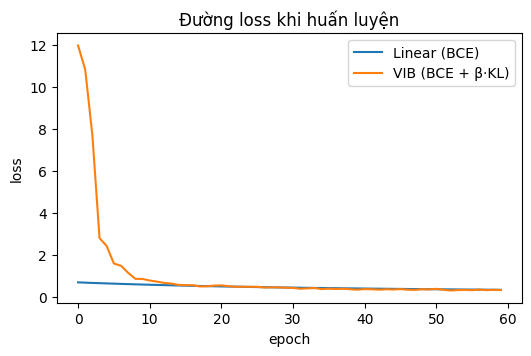

In [6]:
tr_idx = np.where(split == "train")[0]
perm = np.random.RandomState(0).permutation(tr_idx)
fit, held = perm[: int(0.8 * len(perm))], perm[int(0.8 * len(perm)):]

hist_lin, hist_vib = [], []
lin, vibnet = LinearHead(), VIBHead()
t0 = time.time()
train_head(lin, X[fit], y[fit], beta=0.0, seed=0, history=hist_lin)
train_head(vibnet, X[fit], y[fit], beta=1e-2, seed=0, history=hist_vib)
print(f"train xong trong {time.time() - t0:.1f}s")

for name, net in [("Linear", lin), ("VIB beta=0.01", vibnet)]:
    ap, acc = ap_acc(y[held], predict(net, X[held]))
    print(f"{name:14s} held-out SD15: AP={ap*100:.1f}  ACC={acc*100:.1f}")

plt.figure(figsize=(6, 3.5))
plt.plot(hist_lin, label="Linear (BCE)")
plt.plot(hist_vib, label="VIB (BCE + β·KL)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Đường loss khi huấn luyện")
plt.show()

## 6. Thí nghiệm chính: tổng quát hoá sang generator chưa gặp

- Mô hình: Linear (kiểu Univfd) và VIB với β ∈ {0, 1e-4, 1e-3, 1e-2, 1e-1}.
- 3 seed, báo mean ± std.
- Mỗi generator lạ được đánh giá trên tập **cân bằng 1:1** (80 thật + 80 giả), nên **mức ngẫu nhiên = 50%** cho cả AP và ACC.
- β và số epoch **không** được chọn dựa trên tập unseen.

Mất khoảng 1–3 phút trên CPU.

In [7]:
SEEDS = [0, 1, 2]
BETAS = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
UNSEEN = ["ADM", "BigGAN", "GLIDE", "Midjourney", "VQDM", "Wukong"]
un_real = np.where((split == "unseen") & (y == 0))[0]
un_fake = {g: np.where((split == "unseen") & (gen == g))[0] for g in UNSEEN}

models = {"Linear (Univfd-like)": (LinearHead, 0.0)}
models.update({f"VIB beta={b:g}": (VIBHead, b) for b in BETAS})

rows = []
t0 = time.time()
for seed in SEEDS:
    rng = np.random.RandomState(seed)
    perm = rng.permutation(tr_idx)
    fit, held = perm[: int(0.8 * len(perm))], perm[int(0.8 * len(perm)):]
    for name, (cls, beta) in models.items():
        net = cls()
        train_head(net, X[fit], y[fit], beta=beta, seed=seed)
        ap, acc = ap_acc(y[held], predict(net, X[held]))
        rows.append(dict(model=name, seed=seed, test="In-dist (SD15)", AP=ap * 100, ACC=acc * 100))
        for g in UNSEEN:
            idx = np.concatenate([rng.choice(un_real, len(un_fake[g]), replace=False), un_fake[g]])
            ap, acc = ap_acc(y[idx], predict(net, X[idx]))
            rows.append(dict(model=name, seed=seed, test=g, AP=ap * 100, ACC=acc * 100))
print(f"xong trong {time.time() - t0:.0f}s")

res = pd.DataFrame(rows)
unseen_mean = res[res.test.isin(UNSEEN)].groupby(["model", "seed"])[["AP", "ACC"]].mean().reset_index()
unseen_mean["test"] = "Unseen mean"
res = pd.concat([res, unseen_mean], ignore_index=True)
order = ["In-dist (SD15)"] + UNSEEN + ["Unseen mean"]

xong trong 56s


In [8]:
def table(metric):
    g = res.groupby(["model", "test"])[metric]
    t = (g.mean().round(1).astype(str) + " ± " + g.std(ddof=0).round(1).astype(str)).unstack()[order]
    return t.loc[list(models)]

print("AP (%)"); display(table("AP"))
print("ACC (%) @ ngưỡng 0.5"); display(table("ACC"))

AP (%)


test,In-dist (SD15),ADM,BigGAN,GLIDE,Midjourney,VQDM,Wukong,Unseen mean
model,,,,,,,,
Linear (Univfd-like),94.1 ± 1.7,48.7 ± 1.1,38.5 ± 1.6,63.9 ± 4.3,85.3 ± 0.6,47.5 ± 2.5,89.6 ± 1.3,62.3 ± 0.5
VIB beta=0,94.8 ± 1.5,49.3 ± 3.0,42.3 ± 3.1,66.9 ± 3.5,87.9 ± 0.2,51.5 ± 2.1,92.5 ± 1.0,65.1 ± 1.8
VIB beta=0.0001,95.1 ± 1.1,48.4 ± 0.6,42.5 ± 3.0,70.0 ± 0.7,85.3 ± 1.7,51.2 ± 1.8,91.5 ± 1.4,64.8 ± 0.6
VIB beta=0.001,95.3 ± 1.3,48.7 ± 3.9,41.9 ± 1.2,65.6 ± 2.6,85.6 ± 2.7,51.4 ± 2.2,89.4 ± 2.1,63.8 ± 1.6
VIB beta=0.01,95.5 ± 1.1,49.7 ± 0.3,41.8 ± 2.1,64.8 ± 3.0,84.1 ± 2.2,52.0 ± 3.8,90.2 ± 2.1,63.8 ± 1.6
VIB beta=0.1,95.0 ± 1.2,47.3 ± 1.8,41.0 ± 0.9,62.7 ± 3.3,83.5 ± 0.5,51.6 ± 1.2,89.9 ± 3.5,62.7 ± 1.7


ACC (%) @ ngưỡng 0.5


test,In-dist (SD15),ADM,BigGAN,GLIDE,Midjourney,VQDM,Wukong,Unseen mean
model,,,,,,,,
Linear (Univfd-like),87.9 ± 1.6,47.5 ± 0.5,44.4 ± 1.5,56.0 ± 2.1,78.3 ± 0.3,47.1 ± 2.8,84.4 ± 1.5,59.6 ± 1.1
VIB beta=0,88.3 ± 3.1,49.0 ± 2.5,45.0 ± 3.7,58.8 ± 1.8,79.8 ± 2.1,49.6 ± 1.3,86.9 ± 1.8,61.5 ± 1.6
VIB beta=0.0001,88.3 ± 1.6,50.4 ± 2.4,45.0 ± 2.3,62.1 ± 0.3,78.5 ± 3.9,50.0 ± 1.5,85.4 ± 0.8,61.9 ± 0.7
VIB beta=0.001,88.3 ± 1.6,47.3 ± 3.6,44.6 ± 2.4,59.2 ± 2.8,77.7 ± 2.1,49.0 ± 1.6,84.6 ± 2.4,60.4 ± 2.1
VIB beta=0.01,89.2 ± 1.6,48.5 ± 0.6,43.1 ± 3.2,58.1 ± 1.8,77.5 ± 0.5,49.0 ± 3.1,83.5 ± 0.8,60.0 ± 1.1
VIB beta=0.1,87.1 ± 3.6,46.2 ± 0.5,44.0 ± 1.3,58.5 ± 4.6,77.9 ± 0.6,48.1 ± 2.8,84.8 ± 1.8,59.9 ± 1.8


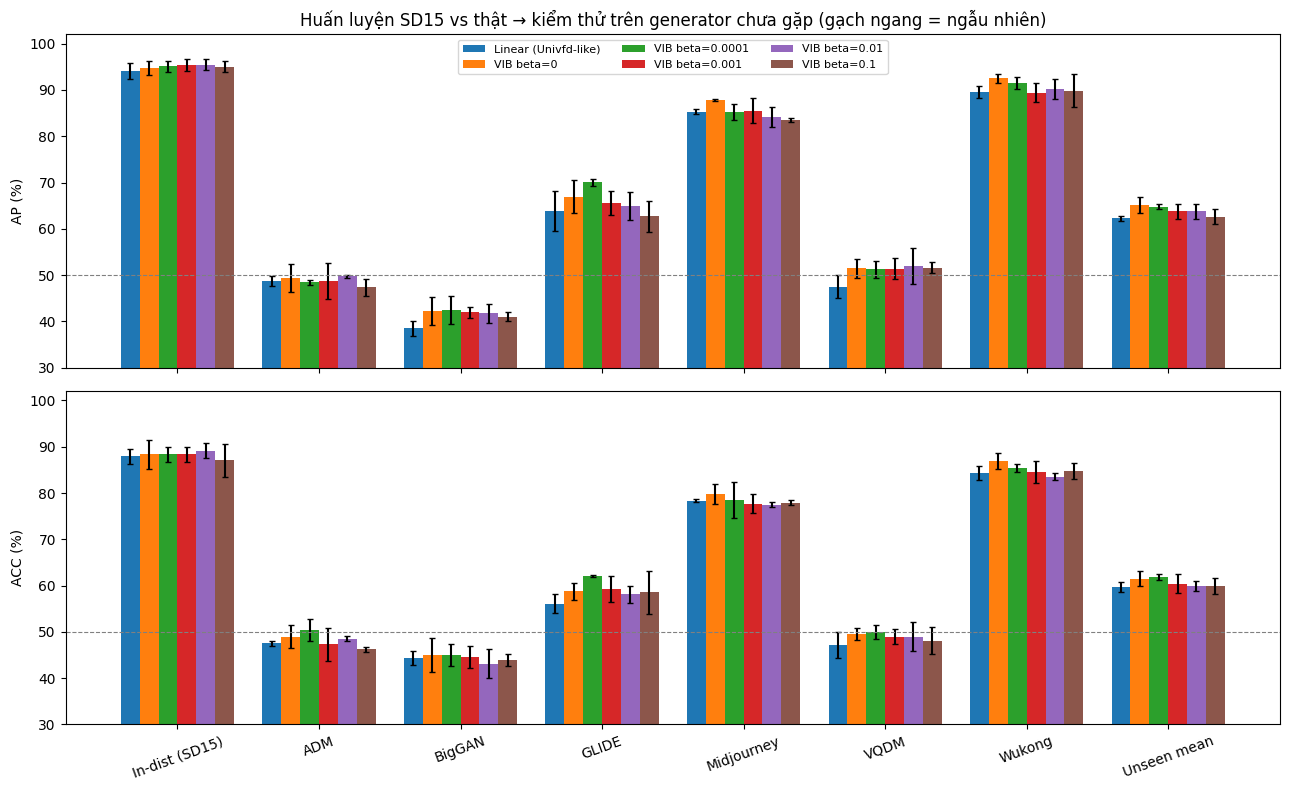

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
w = 0.8 / len(models)
for ax, metric in zip(axes, ["AP", "ACC"]):
    g = res.groupby(["model", "test"])[metric]
    mean, std = g.mean().unstack()[order], g.std(ddof=0).unstack()[order]
    for i, m in enumerate(models):
        ax.bar(np.arange(len(order)) + i * w, mean.loc[m], w, yerr=std.loc[m], capsize=2, label=m)
    ax.axhline(50, color="gray", lw=0.8, ls="--")
    ax.set_ylim(30, 102); ax.set_ylabel(f"{metric} (%)")
axes[0].legend(ncol=3, fontsize=8)
axes[0].set_title("Huấn luyện SD15 vs thật → kiểm thử trên generator chưa gặp (gạch ngang = ngẫu nhiên)")
axes[1].set_xticks(np.arange(len(order)) + 0.4 - w / 2); axes[1].set_xticklabels(order, rotation=20)
plt.tight_layout(); plt.show()

**Cách đọc:**
- Cột *In-dist*: mọi mô hình đều tốt (~94–95 AP), tức là học được SD15.
- Các cột generator lạ: so với vạch 50%. Cột nào gần hoặc dưới 50% nghĩa là mô hình **không** tổng quát hoá được sang generator đó.
- So sánh *Linear* với *VIB β=0* để thấy tác dụng của MLP; so *VIB β=0* với *β>0* để thấy tác dụng riêng của **nút thắt KL**. Chênh lệch nhỏ hơn thanh sai số thì chưa đủ để kết luận.

## 7. UMAP kiểu Hình 3 của bài báo

Bài báo cho thấy đặc trưng CLIP thô tách cụm theo **loại nội dung** (ngữ nghĩa), còn latent của VIB-Net tách theo **thật/giả**.

Tiny-GenImage không có nhãn loại ảnh, nên ta gán nhãn **xấp xỉ** bằng zero-shot CLIP: so điểm với hai câu *"a photo of an animal"* và *"a photo of a man-made object"*, rồi chia theo trung vị để hai nhóm cân bằng.

Cần nạp lại CLIP (khoảng 1 phút, dùng cache). Bản CLIP của repo đã bị tác giả sửa để `Transformer` trả về tuple `(out, x)`, làm hỏng `encode_text`; ta chỉ bọc lại nhánh text, **không sửa repo**.

In [10]:
import clip
clip_model, _ = clip.load("ViT-L/14", device="cpu")
clip_model.eval()
_text_forward = clip_model.transformer.forward            # transformer của nhánh text
clip_model.transformer.forward = lambda x: _text_forward(x)[1]

with torch.no_grad():
    txt = clip_model.encode_text(clip.tokenize(["a photo of an animal", "a photo of a man-made object"])).float()
    txt = txt / txt.norm(dim=-1, keepdim=True)
Xt = torch.as_tensor(X)
diff = ((Xt / Xt.norm(dim=-1, keepdim=True)) @ txt.T).numpy()
diff = diff[:, 1] - diff[:, 0]
tr = split == "train"
cat = (diff > np.median(diff[tr])).astype(int)       # 0: giống động vật, 1: giống vật nhân tạo
print("số ảnh mỗi nhóm (train):", np.bincount(cat[tr]))

C:\Users\HAINAM\AppData\Roaming\Python\Python312\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


số ảnh mỗi nhóm (train): [200 200]


C:\Users\HAINAM\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\HAINAM\AppData\Roaming\Python\Python312\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


C:\Users\HAINAM\AppData\Roaming\Python\Python312\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


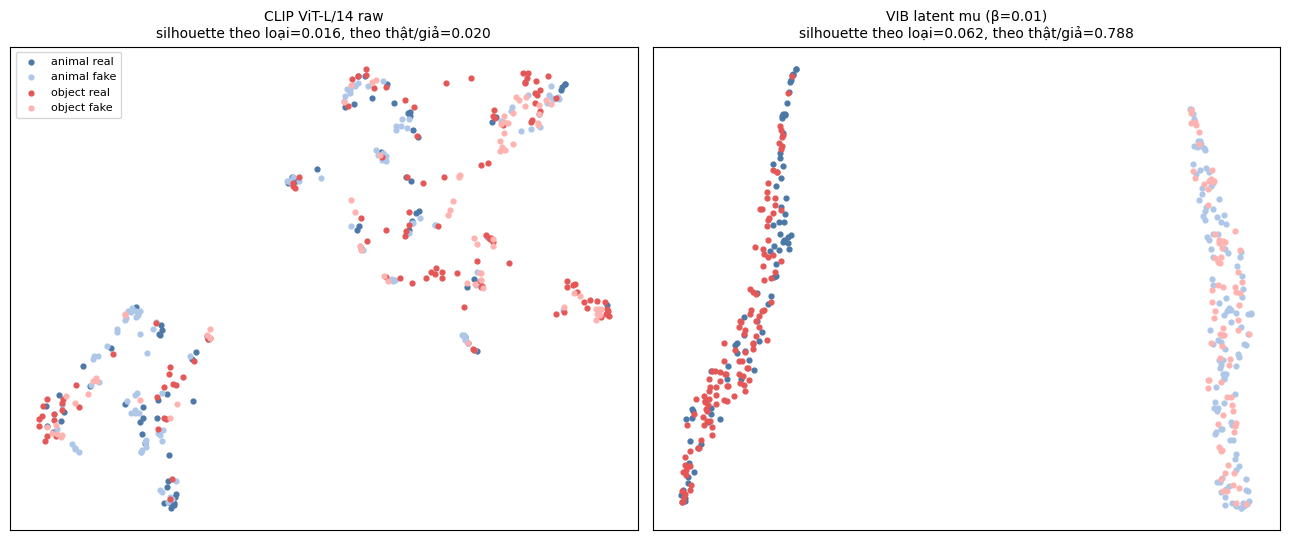

In [11]:
import umap
from sklearn.metrics import silhouette_score

BETA_UMAP = 1e-2
net_u = VIBHead()
train_head(net_u, X[tr], y[tr], beta=BETA_UMAP, seed=0)
net_u.eval()
with torch.no_grad():
    mu_all = net_u.encode(torch.as_tensor(X))[0].numpy()

group = cat[tr] * 2 + y[tr]
names = ["animal real", "animal fake", "object real", "object fake"]
colors = ["#4c78a8", "#aec7e8", "#e45756", "#ffb3b0"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (title, F) in zip(axes, [("CLIP ViT-L/14 raw", X[tr]), (f"VIB latent mu (β={BETA_UMAP:g})", mu_all[tr])]):
    emb = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(F)
    for k in range(4):
        m = group == k
        ax.scatter(emb[m, 0], emb[m, 1], s=12, c=colors[k], label=names[k])
    ax.set_title(f"{title}\nsilhouette theo loại={silhouette_score(F, cat[tr]):.3f}, "
                 f"theo thật/giả={silhouette_score(F, y[tr]):.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lưu ý khi đọc:** UMAP và silhouette ở đây tính **trên chính tập train** mà VIB-head đã học, nên việc `mu` tách thật/giả rõ là điều dễ hiểu và **không** chứng minh khả năng tổng quát hoá. Nhãn "loại ảnh" chỉ là xấp xỉ zero-shot.

## 8. Thử dự đoán trên từng ảnh

Đưa vài ảnh qua toàn bộ pipeline: ảnh → CLIP (đóng băng) → head → xác suất **giả**. Dùng hai head đã huấn luyện ở mục 5. Đây cũng là cách kiểm tra một ảnh bất kỳ của bạn: đổi `paths` thành đường dẫn ảnh khác.

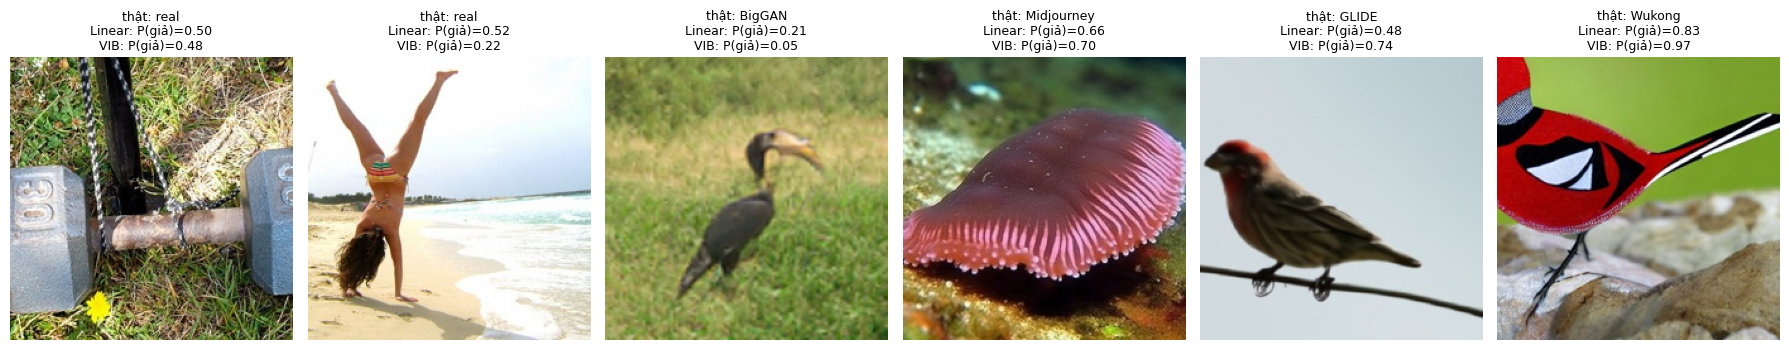

In [12]:
import torchvision.transforms as T

prep = T.Compose([
    T.Resize(256, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224), T.ToTensor(),
    T.Normalize([0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711]),
])

def p_fake(path, heads):
    img = Image.open(path).convert("RGB")
    with torch.no_grad():
        f = clip_model.encode_image(prep(img).unsqueeze(0)).float().numpy()
    return img, {n: float(predict(h, f)[0]) for n, h in heads.items()}

heads = {"Linear": lin, "VIB": vibnet}
rng = np.random.RandomState(1)
picks = [rng.choice(df[(df.split == "unseen") & (df.generator == g)].path.values) for g in ["Real", "Real", "BigGAN", "Midjourney", "GLIDE", "Wukong"]]
paths = [HERE / "data" / p for p in picks]

fig, axes = plt.subplots(1, len(paths), figsize=(3 * len(paths), 3.6))
for ax, p in zip(axes, paths):
    img, probs = p_fake(p, heads)
    ax.imshow(img); ax.axis("off")
    truth = p.parent.name
    ax.set_title(f"thật: {truth}\n" + "\n".join(f"{k}: P(giả)={v:.2f}" for k, v in probs.items()), fontsize=9)
plt.tight_layout(); plt.show()

## 9. Kết luận và giới hạn

**Kết quả lần chạy tham chiếu** (có thể dao động nhẹ khi chạy lại):
- Cùng phân phối (SD15): mọi mô hình đạt khoảng 94–95 AP.
- Trên generator lạ: VIB nhỉnh hơn Linear khoảng 1–3 điểm AP trung bình, nhưng **β>0 không tốt hơn β=0**, và độ chênh gần bằng sai số. Demo này **chưa chứng minh** được tác dụng riêng của nút thắt KL.
- ADM, VQDM, BigGAN gần hoặc dưới mức ngẫu nhiên với mọi mô hình. Demo **không** tái hiện được mức tổng quát hoá của bài (AP ~95 trên 15 generator).

**Giới hạn:**
- Dữ liệu rất nhỏ (400 ảnh train, 80 ảnh mỗi generator lạ) so với bài (32.000 ảnh train).
- Dùng SD15 thay SD v1.4. Wukong cũng thuộc họ SD nên chỉ BigGAN là GAN khác họ thật sự.
- Không dùng checkpoint của tác giả; β, số epoch, augmentation (blur/JPEG lúc train) không theo đúng bài vì bài không công bố đủ chi tiết và repo không có code huấn luyện.
- Nhãn "loại ảnh" trong UMAP là nhãn xấp xỉ.

**Hướng thử tiếp:** tăng dữ liệu train, thêm augmentation blur/JPEG, chạy nhiều seed hơn, hoặc dùng checkpoint SD v1.4 của tác giả với `main.py` để so sánh.